# Validation 5 : Evolution of The Correlation

## 1- Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2- Data Loading

In [2]:
# Load the data
df = pd.read_csv('metrics.csv')

## 3- Iteration Scenarios and Correlation Calculation

Here's a list to store correlation results and the different rule scenarios:

In [12]:
correlations = []

rule_scenarios = [
    {
        'LC': "(SLOC>=16 and CC>=12) or VOL>= 62",
        'LEC' : "LOEC>=14 or DNA>= 3",
        'CCC':"LOOP_CONDITION >=3",
        'LE': "NOCE>=96",
        'CIC': 'DNIC>=3'
    },
    {
        'LC': "(SLOC>=16 and CC>=12) or VOL>= 62",
        'LEC' : "LOEC>=14 or DNA>= 3",
        'CCC':"LOOP_CONDITION >=3",
        'LE': "NOCE>=96",
        'CIC': 'NOIC>=6 or DNIC>=3'

    },
    {
        'LC': "(SLOC>=16 and CC>=12) or VOL>= 62",
        'LEC' : "LOEC>=10 or DNA>= 1",
        'CCC':"LOOP_CONDITION >=2",
        'LE': "NOCE>=96",
        'CIC': 'NOIC>=3 or DNIC>=2'
 
    },
    {
        'LC': "(SLOC>=16 and CC>=12) or VOL>= 62",
        'LEC' : "LOEC>=10 or DNA>= 1",
        'CCC':"LOOP_CONDITION >=2",
        'LE': "NOCE>=96",
        'CIC': 'NOIC>=3 or DNIC>=2'
        
    },
    {
        'LC': "(SLOC>=13 and CC>=10) or (SLOC>=13 and FC>=10) or VOL>= 60",
        'LEC' : "LOEC>=10 or DNA>= 1",
        'CCC':"LOOP_CONDITION >=2",
        'LE': "NOCE>=90 or (METHODS>=2 and ARGS>=3)",
        'CIC': 'NOIC>=3 or DNIC>=2'
    },
    {
        'LC': "(SLOC>=13 and CC>=10) or (SLOC>=13 and FC>=10) or VOL>= 60",
        'LEC' : "LOEC>=7 or DNA>= 1 ",
        'CCC':"LOOP_CONDITION >=1",
        'LE': "NOCE>=80 or METHODS_ARGS>=3",
        'CIC': 'NOIC>=3 or DNIC>=2'

    },
    {
        'LC': "(SLOC>=13 and CC_FC>=10) or (VOL>= 30 and SLOC>=13)",
        'LEC' : "LOEC>=7 or DNA>= 1 ",
        'CCC':"LOOP_CONDITION >=1",
        'LE': "NOCE>=90",
        'CIC': 'NOIC>=3 or DNIC>=2'
    },
    {
        'LC': "(SLOC>=13 and CC_FC>=10) or (VOL>= 30 and SLOC>=13)",
        'LEC' : "LOEC>=7 or DNA>= 2 ",
        'CCC':"LOOP_CONDITION>= 1 and LOC>=50",
        'LE': "NOCE>=87  ",
        'CIC': 'NOIC>=3 or DNIC>=2'
    }
]

For each scenario, apply the rules and compute the Pearson correlation:

In [13]:
# Convert relevant columns to numeric data type
cols_to_convert = ['SLOC', 'CC', 'FC', 'CC_FC', 'VOL', 'LOOP_CONDITION', 'LOC', 'DNA', 'LOEC', 'NOCE', 'METHODS', 'ARGS', 'METHODS_ARGS', 'DNIC', 'NOIC']
for col in cols_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Now, apply the rules and calculate correlations
correlations = []
for iteration_num, rules in enumerate(rule_scenarios, 1):
    for smell, rule in rules.items():
        df['calculated_code_smell'] = df.eval(rule)
        pearson_corr = df['calculated_code_smell'].corr(df[smell], method='pearson')
        correlations.append((iteration_num, smell, pearson_corr))

# Convert the correlations list to a DataFrame for easier manipulation
correlations_df = pd.DataFrame(correlations, columns=["Iteration", "Code_Smell", "Pearson_Correlation"])

## 5- Plotting the Correlation Trends

Plotting the trend of correlations for different code smells across the iterations:

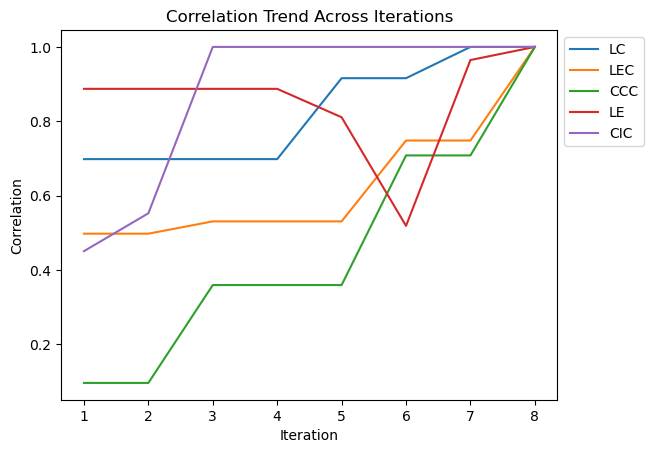

In [14]:
for smell in correlations_df['Code_Smell'].unique():
    subset = correlations_df[correlations_df['Code_Smell'] == smell]
    plt.plot(subset['Iteration'], subset['Pearson_Correlation'], label=smell)

plt.xlabel('Iteration')
plt.ylabel('Correlation')
plt.title('Correlation Trend Across Iterations')
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()